# Combined Human3.6M + MPI-INF-3DHP — 2D to 3D Pose Estimation

Training on both datasets combined from scratch for maximum generalization.

| Dataset | Subjects | Samples |
|---|---|---|
| Human3.6M | S1,S5,S6,S7,S8,S9,S11 | ~1.96M |
| MPI-INF-3DHP | S1–S8 | ~131K |
| **Combined** | **—** | **~2.09M** |

**Pipeline:** Both datasets → unified 17-joint space → combined DataLoader → Stage 1 MSE → Stage 2 Anatomy


In [1]:
import os, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import scipy.io as sio
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch : {torch.__version__}")
print(f"Device  : {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU     : {torch.cuda.get_device_name(0)}")
    print(f"VRAM    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")


PyTorch : 2.5.1+cu121
Device  : cuda
GPU     : NVIDIA GeForce RTX 3060 Laptop GPU
VRAM    : 6.4 GB


In [2]:
# ─── Paths ────────────────────────────────────────────────────────────────────
H36M_ANNOT_DIR = r'C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\annotations'
MPI_DIR        = r'C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi'

# ─── Hyperparameters ──────────────────────────────────────────────────────────
S1_EPOCHS  = 80
S2_EPOCHS  = 30
BATCH_SIZE = 2048
LR_S1      = 0.001
LR_S2      = 1e-4
NUM_CAMS   = 4

# ─── Joint definitions ────────────────────────────────────────────────────────
# MPI-INF-3DHP (28 joints) → H3.6M 17-joint order
MPI_TO_H36M = [4, 23, 24, 25, 18, 19, 20, 3, 5, 6, 7, 9, 10, 11, 14, 15, 16]

JOINT_NAMES = [
    "Pelvis","R.Hip","R.Knee","R.Ankle",
    "L.Hip","L.Knee","L.Ankle","Spine",
    "Thorax","Neck","Head",
    "L.Shoulder","L.Elbow","L.Wrist",
    "R.Shoulder","R.Elbow","R.Wrist"
]

BONES = [
    (0,1),(1,2),(2,3),
    (0,4),(4,5),(5,6),
    (0,7),(7,8),(8,9),(9,10),
    (8,11),(11,12),(12,13),
    (8,14),(14,15),(15,16),
]

print("Config ready.")
print(f"H36M annotations : {H36M_ANNOT_DIR}")
print(f"MPI dataset      : {MPI_DIR}")


Config ready.
H36M annotations : C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\annotations
MPI dataset      : C:\Ahmed\UNI\SEM 8\FYP\FYP--2\Dataset\mpi_inf_3dhp\dataset\mpi


In [11]:
# ─── Human3.6M Dataset ───────────────────────────────────────────────────────
class Human36MDataset(Dataset):
    """
    Loads Human3.6M annotation JSONs.
    Projects 3D ground truth → 2D using camera parameters.
    Output: X (136,), Y (51,) — same space as MPI dataset.
    """
    H36M_JOINTS = 17  # already 17-joint format in annotations

    def __init__(self, annot_dir, subjects, num_cams=4, use_cache=True):
        self.root_idx = 0
        tag  = "_".join(f"S{s}" for s in sorted(subjects))
        self.cache = f"h36m_cache_{tag}_cams{num_cams}.pt"

        if use_cache and os.path.exists(self.cache):
            print(f"  ✓ H36M cache hit: {self.cache}")
            d = torch.load(self.cache)
            self.X, self.Y = d['X'], d['Y']
            return

        print(f"  Building H36M dataset for {subjects}...")
        Xl, Yl = [], []

        for s in subjects:
            cam_path  = os.path.join(annot_dir, f'Human36M_subject{s}_camera.json')
            j3d_path  = os.path.join(annot_dir, f'Human36M_subject{s}_joint_3d.json')

            if not os.path.exists(cam_path) or not os.path.exists(j3d_path):
                print(f"    ⚠ Missing files for S{s}, skipping.")
                continue

            with open(cam_path)  as f: cameras  = json.load(f)
            with open(j3d_path)  as f: joints3d = json.load(f)

            cam_ids = list(cameras.keys())[:num_cams]

            # Build camera projection matrices
            cam_params = []
            for cid in cam_ids:
                c = cameras[cid]
                R = np.array(c['R'],  dtype=np.float32)
                t = np.array(c['t'],  dtype=np.float32).reshape(3)
                f = np.array(c['f'],  dtype=np.float32).reshape(2)
                cp= np.array(c['c'],  dtype=np.float32).reshape(2)
                cam_params.append((R, t, f, cp))

            # Iterate actions → subactions → frames
            count = 0
            for action in joints3d:
                for subaction in joints3d[action]:
                    frames = joints3d[action][subaction]
                    for frame_key in frames:
                        frame_data = frames[frame_key]
                        p3d = np.array(frame_data, dtype=np.float32).reshape(17, 3)
                        p3d_centered = p3d - p3d[self.root_idx]

                        views = []
                        for R, t, f_cam, c_cam in cam_params:
                            # Project 3D → 2D
                            X_cam = p3d @ R.T + t
                            x2d   = X_cam[:, :2] / X_cam[:, 2:3]
                            u     = x2d[:, 0] * f_cam[0] + c_cam[0]
                            v     = x2d[:, 1] * f_cam[1] + c_cam[1]
                            p2d   = np.stack([u, v], axis=1)
                            p2d  -= p2d[self.root_idx]
                            views.append(p2d.reshape(-1))

                        Xl.append(np.concatenate(views).astype(np.float32))
                        Yl.append(p3d_centered.reshape(-1).astype(np.float32))
                        count += 1

            print(f"    S{s}: {count:,} frames")

        self.X = torch.tensor(np.array(Xl), dtype=torch.float32)
        self.Y = torch.tensor(np.array(Yl), dtype=torch.float32)

        if use_cache:
            torch.save({'X': self.X, 'Y': self.Y}, self.cache)
            print(f"  ✓ H36M cache saved: {self.cache}")

        print(f"  H36M total: {len(self.X):,} samples")

    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.Y[i]


In [12]:
# ─── MPI-INF-3DHP Dataset ────────────────────────────────────────────────────
class MPIINFDataset(Dataset):
    """
    Loads MPI-INF-3DHP annot.mat files.
    Uses dataset's own 2D annotations (annot2) directly.
    Output: X (136,), Y (51,) — same space as H36M dataset.
    """
    def __init__(self, data_dir, subjects, num_cams=4, use_cache=True):
        self.root_idx = 0
        tag  = "_".join(map(str, sorted(subjects)))
        self.cache = f"mpi_cache_subs_{tag}_cams{num_cams}.pt"

        if use_cache and os.path.exists(self.cache):
            print(f"  ✓ MPI cache hit: {self.cache}")
            d = torch.load(self.cache)
            self.X, self.Y = d['X'], d['Y']
            return

        print(f"  Building MPI dataset for subjects {subjects}...")
        Xl, Yl = [], []

        for s in subjects:
            for seq in [1, 2]:
                path = os.path.join(data_dir, f'S{s}', f'Seq{seq}', 'annot.mat')
                if not os.path.exists(path):
                    print(f"    ⚠ Missing: {path}")
                    continue
                mat  = sio.loadmat(path)
                ann2 = mat['annot2']
                ann3 = mat['annot3']
                nf   = ann3[0, 0].shape[0]
                gt3  = ann3[0, 0]
                print(f"    S{s}/Seq{seq}: {nf:,} frames")

                for fr in range(nf):
                    views = []
                    for c in range(num_cams):
                        p2 = ann2[c,0][fr].reshape(28,2).astype(np.float32)
                        p2 = p2[MPI_TO_H36M]
                        p2 -= p2[self.root_idx]
                        views.append(p2.reshape(-1))
                    X = np.concatenate(views).astype(np.float32)

                    p3 = gt3[fr].reshape(28,3).astype(np.float32)
                    p3 = p3[MPI_TO_H36M]
                    p3 -= p3[self.root_idx]
                    Y  = p3.reshape(-1).astype(np.float32)

                    Xl.append(X); Yl.append(Y)

        self.X = torch.tensor(np.array(Xl), dtype=torch.float32)
        self.Y = torch.tensor(np.array(Yl), dtype=torch.float32)

        if use_cache:
            torch.save({'X': self.X, 'Y': self.Y}, self.cache)
            print(f"  ✓ MPI cache saved: {self.cache}")

        print(f"  MPI total: {len(self.X):,} samples")

    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.Y[i]


In [13]:
# ─── Load All Datasets & Combine ─────────────────────────────────────────────
print("="*60)
print("Loading Human3.6M...")
print("="*60)

# H36M splits: train S1,S5,S6,S7 | val S8,S9 | test S11
h36m_train = Human36MDataset(H36M_ANNOT_DIR, subjects=[1,5,6,7], num_cams=NUM_CAMS)
h36m_val   = Human36MDataset(H36M_ANNOT_DIR, subjects=[8,9],     num_cams=NUM_CAMS)
h36m_test  = Human36MDataset(H36M_ANNOT_DIR, subjects=[11],      num_cams=NUM_CAMS)

print()
print("="*60)
print("Loading MPI-INF-3DHP...")
print("="*60)

# MPI splits: train S1-S6 | val S7 | test S8
mpi_train = MPIINFDataset(MPI_DIR, subjects=[1,2,3,4,5,6], num_cams=NUM_CAMS)
mpi_val   = MPIINFDataset(MPI_DIR, subjects=[7],           num_cams=NUM_CAMS)
mpi_test  = MPIINFDataset(MPI_DIR, subjects=[8],           num_cams=NUM_CAMS)

print()
print("="*60)
print("Combining datasets...")
print("="*60)

# Combine using ConcatDataset — no reprocessing needed
combined_train = ConcatDataset([h36m_train, mpi_train])
combined_val   = ConcatDataset([h36m_val,   mpi_val])
combined_test  = ConcatDataset([h36m_test,  mpi_test])

train_loader = DataLoader(combined_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(combined_val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(combined_test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"\n{'='*60}")
print(f"  H36M  train (S1,5,6,7)  : {len(h36m_train):>10,}")
print(f"  MPI   train (S1–S6)     : {len(mpi_train):>10,}")
print(f"  Combined train          : {len(combined_train):>10,}")
print(f"  Combined val            : {len(combined_val):>10,}")
print(f"  Combined test           : {len(combined_test):>10,}")
print(f"{'='*60}")


Loading Human3.6M...
  Building H36M dataset for [1, 5, 6, 7]...
    S1: 62,094 frames
    S5: 99,079 frames
    S6: 62,466 frames
    S7: 101,621 frames
  ✓ H36M cache saved: h36m_cache_S1_S5_S6_S7_cams4.pt
  H36M total: 325,260 samples
  Building H36M dataset for [8, 9]...
    S8: 64,678 frames
    S9: 79,417 frames
  ✓ H36M cache saved: h36m_cache_S8_S9_cams4.pt
  H36M total: 144,095 samples
  Building H36M dataset for [11]...
    S11: 58,244 frames
  ✓ H36M cache saved: h36m_cache_S11_cams4.pt
  H36M total: 58,244 samples

Loading MPI-INF-3DHP...
  ✓ MPI cache hit: mpi_cache_subs_1_2_3_4_5_6_cams4.pt
  ✓ MPI cache hit: mpi_cache_subs_7_cams4.pt
  ✓ MPI cache hit: mpi_cache_subs_8_cams4.pt

Combining datasets...

  H36M  train (S1,5,6,7)  :    325,260
  MPI   train (S1–S6)     :    106,512
  Combined train          :    431,772
  Combined val            :    156,654
  Combined test           :     70,766


In [14]:
# ─── Model ───────────────────────────────────────────────────────────────────
class ResidualBlock(nn.Module):
    def __init__(self, h=1024, p=0.5):
        super().__init__()
        self.block = nn.Sequential(
            nn.Linear(h,h), nn.BatchNorm1d(h), nn.ReLU(True), nn.Dropout(p),
            nn.Linear(h,h), nn.BatchNorm1d(h),
        )
        self.act = nn.ReLU(True)
    def forward(self, x):
        return self.act(self.block(x) + x)


class MultiViewLiftingMLP(nn.Module):
    """136 → [1024 × 4 ResBlocks] → 51"""
    def __init__(self, in_dim=136, hidden=1024, out_dim=51):
        super().__init__()
        self.entry = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(True), nn.Dropout(0.5)
        )
        self.res  = nn.ModuleList([ResidualBlock(hidden) for _ in range(4)])
        self.head = nn.Linear(hidden, out_dim)

    def forward(self, x):
        x = self.entry(x)
        for blk in self.res: x = blk(x)
        return self.head(x)


model  = MultiViewLiftingMLP().to(DEVICE)
total  = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model parameters : {total:,}")
print(f"Device           : {next(model.parameters()).device}")


Model parameters : 8,607,795
Device           : cuda:0


In [15]:
# ─── Anatomy Loss ────────────────────────────────────────────────────────────
BONE_PAIRS = [
    (0,1),(1,2),(2,3),(0,4),(4,5),(5,6),
    (0,7),(7,8),(8,9),(9,10),
    (8,11),(11,12),(12,13),(8,14),(14,15),(15,16),
]
SYMMETRY_PAIRS = [
    ((0,1),(0,4)),((1,2),(4,5)),((2,3),(5,6)),
    ((8,11),(8,14)),((11,12),(14,15)),((12,13),(15,16)),
]

def anatomy_loss(pred, target):
    pred   = pred.view(-1,17,3)
    target = target.view(-1,17,3)
    mse  = F.mse_loss(pred, target)
    bone = sum(F.mse_loss(
        torch.norm(pred[:,i]-pred[:,j],dim=1),
        torch.norm(target[:,i]-target[:,j],dim=1))
        for i,j in BONE_PAIRS) / len(BONE_PAIRS)
    sym  = sum(F.mse_loss(
        torch.norm(pred[:,l[0]]-pred[:,l[1]],dim=1),
        torch.norm(pred[:,r[0]]-pred[:,r[1]],dim=1))
        for l,r in SYMMETRY_PAIRS) / len(SYMMETRY_PAIRS)
    return mse + 0.1*bone + 0.05*sym, mse, bone, sym

print("✅ Anatomy loss ready.")


✅ Anatomy loss ready.


In [16]:
# ─── Stage 1: MSE Training (80 epochs) ───────────────────────────────────────
model     = MultiViewLiftingMLP().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR_S1)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min',
                                                         factor=0.5, patience=8)
criterion = nn.MSELoss()

best_val = float('inf')
s1_train_losses, s1_val_mpjpes = [], []

print(f"Stage 1 — {S1_EPOCHS} epochs | batch {BATCH_SIZE} | lr {LR_S1}")
print(f"Train samples: {len(combined_train):,}")
print(f"{'='*72}")

for epoch in range(S1_EPOCHS):
    # Train
    model.train()
    t_loss = 0.0
    for Xb, Yb in train_loader:
        Xb, Yb = Xb.to(DEVICE), Yb.to(DEVICE)
        loss = criterion(model(Xb), Yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        t_loss += loss.item()

    # Validate — full pass
    model.eval()
    all_v = []
    with torch.no_grad():
        for Xv, Yv in val_loader:
            Xv, Yv = Xv.to(DEVICE), Yv.to(DEVICE)
            d = torch.norm(model(Xv).view(-1,17,3) - Yv.view(-1,17,3), dim=2)
            all_v.append(d.cpu())
    avg_v = torch.cat(all_v).mean().item()

    avg_t = t_loss / len(train_loader)
    s1_train_losses.append(avg_t)
    s1_val_mpjpes.append(avg_v)

    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(avg_v)
    new_lr = optimizer.param_groups[0]['lr']

    tag = ""
    if avg_v < best_val:
        best_val = avg_v
        torch.save(model.state_dict(), 'best_combined_stage1.pth')
        tag = "  ⭐"
    if new_lr < old_lr:
        tag += f"  📉 lr→{new_lr:.2e}"

    print(f"Ep [{epoch+1:>3}/{S1_EPOCHS}]  Loss: {avg_t:>10.2f}  Val MPJPE: {avg_v:>7.2f}mm{tag}")

print(f"\n✅ Stage 1 done. Best Val MPJPE: {best_val:.2f}mm")

# Test on unseen subjects
model.load_state_dict(torch.load('best_combined_stage1.pth'))
model.eval()
all_t = []
with torch.no_grad():
    for Xt, Yt in test_loader:
        Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
        d = torch.norm(model(Xt).view(-1,17,3) - Yt.view(-1,17,3), dim=2)
        all_t.append(d.cpu())
s1_test_mpjpe = torch.cat(all_t).mean().item()
print(f"Stage 1 MPJPE on unseen test: {s1_test_mpjpe:.2f}mm")


Stage 1 — 80 epochs | batch 2048 | lr 0.001
Train samples: 431,772
Ep [  1/80]  Loss:   35260.68  Val MPJPE:  151.16mm  ⭐
Ep [  2/80]  Loss:    7074.86  Val MPJPE:  162.34mm
Ep [  3/80]  Loss:    3549.71  Val MPJPE:   65.17mm  ⭐
Ep [  4/80]  Loss:    2468.23  Val MPJPE:   65.28mm
Ep [  5/80]  Loss:    1983.31  Val MPJPE:  142.58mm
Ep [  6/80]  Loss:    1821.19  Val MPJPE:   52.19mm  ⭐
Ep [  7/80]  Loss:    1626.88  Val MPJPE:   49.95mm  ⭐
Ep [  8/80]  Loss:    1527.21  Val MPJPE:   45.00mm  ⭐
Ep [  9/80]  Loss:    1368.67  Val MPJPE:  154.60mm
Ep [ 10/80]  Loss:    1311.91  Val MPJPE:  219.94mm
Ep [ 11/80]  Loss:    1300.40  Val MPJPE:  171.16mm
Ep [ 12/80]  Loss:    1290.28  Val MPJPE:   43.18mm  ⭐
Ep [ 13/80]  Loss:    1199.04  Val MPJPE:   60.12mm
Ep [ 14/80]  Loss:    1126.44  Val MPJPE:   51.59mm
Ep [ 15/80]  Loss:    1122.37  Val MPJPE:   49.49mm
Ep [ 16/80]  Loss:    1082.75  Val MPJPE:   44.69mm
Ep [ 17/80]  Loss:    1002.36  Val MPJPE:  187.43mm
Ep [ 18/80]  Loss:    1066.41  

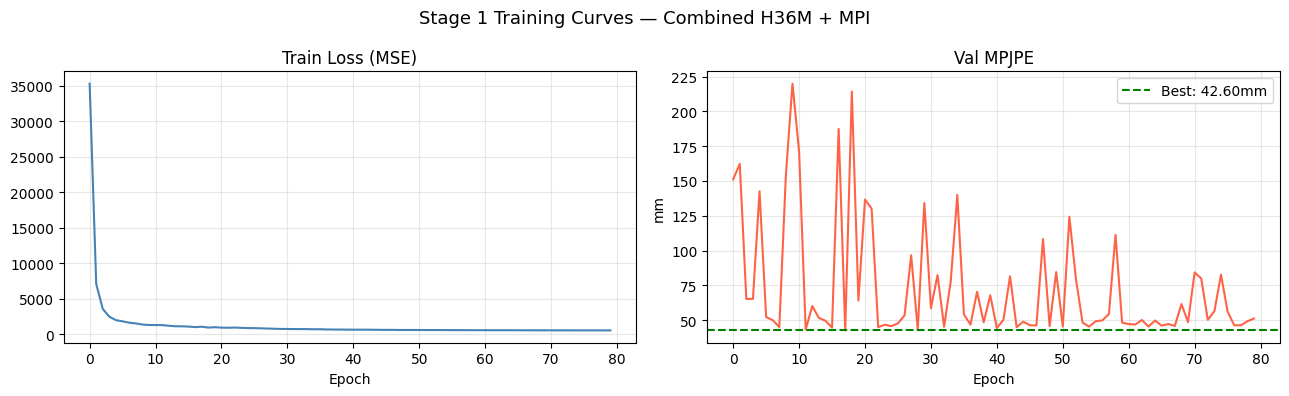

Saved: combined_stage1_curves.png


In [17]:
# ─── Stage 1 Learning Curves ─────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13,4))
fig.suptitle("Stage 1 Training Curves — Combined H36M + MPI", fontsize=13)

ax1.plot(s1_train_losses, color='steelblue')
ax1.set_title("Train Loss (MSE)"); ax1.set_xlabel("Epoch"); ax1.grid(alpha=0.3)

ax2.plot(s1_val_mpjpes, color='tomato')
ax2.axhline(best_val, linestyle='--', color='green', label=f'Best: {best_val:.2f}mm')
ax2.set_title("Val MPJPE"); ax2.set_xlabel("Epoch"); ax2.set_ylabel("mm")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("combined_stage1_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: combined_stage1_curves.png")


In [18]:
# ─── Stage 2: Anatomical Fine-Tuning (30 epochs) ─────────────────────────────
# Expand train to include val subjects too
h36m_s2_train = Human36MDataset(H36M_ANNOT_DIR, subjects=[1,5,6,7,8,9], num_cams=NUM_CAMS)
mpi_s2_train  = MPIINFDataset(MPI_DIR,          subjects=[1,2,3,4,5,6,7], num_cams=NUM_CAMS)

s2_train = ConcatDataset([h36m_s2_train, mpi_s2_train])
s2_test  = combined_test   # same unseen test set

s2_train_loader = DataLoader(s2_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=True)
s2_test_loader  = DataLoader(s2_test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f"Stage 2 train: {len(s2_train):,}  |  test: {len(s2_test):,}")

s2_model = MultiViewLiftingMLP().to(DEVICE)
s2_model.load_state_dict(torch.load('best_combined_stage1.pth', map_location=DEVICE))

s2_opt   = torch.optim.Adam(s2_model.parameters(), lr=LR_S2)
s2_sched = torch.optim.lr_scheduler.ReduceLROnPlateau(s2_opt, mode='min', factor=0.5, patience=4)

best_s2 = float('inf')
s2_test_mpjpes = []

print(f"\nStage 2 — {S2_EPOCHS} epochs | lr {LR_S2}")
print(f"{'='*75}")

for epoch in range(S2_EPOCHS):
    s2_model.train()
    el = em = eb = es = 0.0
    for Xb, Yb in s2_train_loader:
        Xb, Yb = Xb.to(DEVICE), Yb.to(DEVICE)
        total, mse, bone, sym = anatomy_loss(s2_model(Xb), Yb)
        s2_opt.zero_grad(); total.backward(); s2_opt.step()
        el+=total.item(); em+=mse.item(); eb+=bone.item(); es+=sym.item()

    n = len(s2_train_loader)
    el/=n; em/=n; eb/=n; es/=n

    s2_model.eval()
    all_t = []
    with torch.no_grad():
        for Xt, Yt in s2_test_loader:
            Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
            d = torch.norm(s2_model(Xt).view(-1,17,3) - Yt.view(-1,17,3), dim=2)
            all_t.append(d.cpu())
    avg_t = torch.cat(all_t).mean().item()
    s2_test_mpjpes.append(avg_t)
    s2_sched.step(avg_t)

    tag = ""
    if avg_t < best_s2:
        best_s2 = avg_t
        torch.save(s2_model.state_dict(), 'best_combined_stage2.pth')
        tag = "  ⭐"

    print(f"Ep [{epoch+1:>2}/{S2_EPOCHS}]  Loss:{el:.2f}  MSE:{em:.2f}  "
          f"Bone:{eb:.2f}  Sym:{es:.2f}  |  Test MPJPE:{avg_t:.2f}mm{tag}")

print(f"\n✅ Stage 2 done. Best MPJPE: {best_s2:.2f}mm")


  Building H36M dataset for [1, 5, 6, 7, 8, 9]...
    S1: 62,094 frames
    S5: 99,079 frames
    S6: 62,466 frames
    S7: 101,621 frames
    S8: 64,678 frames
    S9: 79,417 frames
  ✓ H36M cache saved: h36m_cache_S1_S5_S6_S7_S8_S9_cams4.pt
  H36M total: 469,355 samples
  ✓ MPI cache hit: mpi_cache_subs_1_2_3_4_5_6_7_cams4.pt
Stage 2 train: 588,426  |  test: 70,766

Stage 2 — 30 epochs | lr 0.0001
Ep [ 1/30]  Loss:1031.84  MSE:955.78  Bone:450.77  Sym:619.55  |  Test MPJPE:205.74mm  ⭐
Ep [ 2/30]  Loss:952.15  MSE:883.78  Bone:406.70  Sym:553.86  |  Test MPJPE:36.38mm  ⭐
Ep [ 3/30]  Loss:914.78  MSE:849.97  Bone:387.12  Sym:521.96  |  Test MPJPE:36.39mm
Ep [ 4/30]  Loss:888.76  MSE:826.63  Bone:371.32  Sym:499.98  |  Test MPJPE:37.10mm
Ep [ 5/30]  Loss:862.58  MSE:802.57  Bone:358.50  Sym:483.29  |  Test MPJPE:38.20mm
Ep [ 6/30]  Loss:850.20  MSE:791.85  Bone:348.22  Sym:470.66  |  Test MPJPE:36.89mm
Ep [ 7/30]  Loss:836.15  MSE:779.11  Bone:341.80  Sym:457.16  |  Test MPJPE:36.41mm
E

In [19]:
# ─── Final Evaluation ─────────────────────────────────────────────────────────
final = MultiViewLiftingMLP().to(DEVICE)
final.load_state_dict(torch.load('best_combined_stage2.pth', map_location=DEVICE))
final.eval()

all_dists = []
with torch.no_grad():
    for Xt, Yt in s2_test_loader:
        Xt, Yt = Xt.to(DEVICE), Yt.to(DEVICE)
        d = torch.norm(final(Xt).view(-1,17,3) - Yt.view(-1,17,3), dim=2)
        all_dists.append(d.cpu())

all_dists = torch.cat(all_dists, dim=0)
mpjpe     = all_dists.mean().item()
pck       = {t: (all_dists < t).float().mean().item()*100 for t in [50,100,150,200]}
per_joint = all_dists.mean(dim=0).numpy()

print("="*60)
print("   FINAL EVALUATION — H36M + MPI Combined (unseen test)")
print("="*60)
print(f"  MPJPE (mean) : {mpjpe:.2f} mm")
for t,v in pck.items():
    print(f"  PCK@{t}mm    : {v:.2f}%")
print()
df = pd.DataFrame({'Joint': JOINT_NAMES, 'MPJPE (mm)': np.round(per_joint,2)})
print(df.to_string(index=False))
print("="*60)


   FINAL EVALUATION — H36M + MPI Combined (unseen test)
  MPJPE (mean) : 35.83 mm
  PCK@50mm    : 79.06%
  PCK@100mm    : 95.37%
  PCK@150mm    : 98.82%
  PCK@200mm    : 99.59%

     Joint  MPJPE (mm)
    Pelvis    0.520000
     R.Hip   15.430000
    R.Knee   42.790001
   R.Ankle   49.310001
     L.Hip   15.810000
    L.Knee   35.660000
   L.Ankle   50.450001
     Spine   23.100000
    Thorax   32.259998
      Neck   40.790001
      Head   54.330002
L.Shoulder   36.880001
   L.Elbow   39.820000
   L.Wrist   43.619999
R.Shoulder   38.130001
   R.Elbow   43.330002
   R.Wrist   46.820000


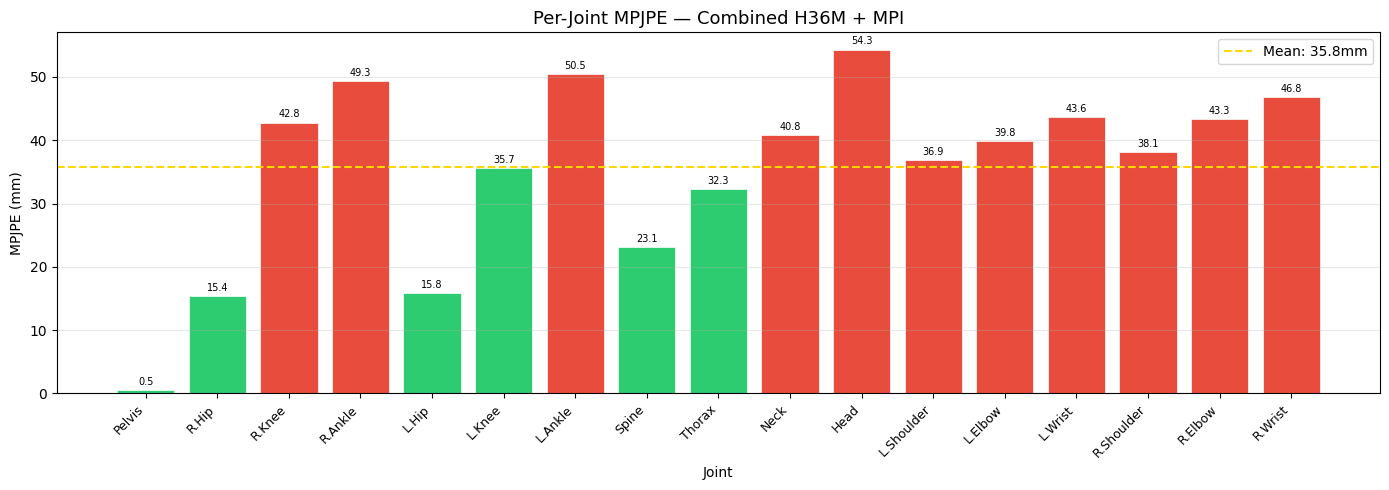

Saved: combined_per_joint_mpjpe.png


In [20]:
# ─── Per-Joint Bar Chart ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14,5))
colors  = ['#E74C3C' if v > mpjpe else '#2ECC71' for v in per_joint]
bars    = ax.bar(JOINT_NAMES, per_joint, color=colors, edgecolor='white', linewidth=0.5)
ax.axhline(mpjpe, color='gold', linestyle='--', linewidth=1.5, label=f'Mean: {mpjpe:.1f}mm')
ax.set_title("Per-Joint MPJPE — Combined H36M + MPI", fontsize=13)
ax.set_ylabel("MPJPE (mm)"); ax.set_xlabel("Joint")
plt.xticks(rotation=45, ha='right', fontsize=9)
ax.legend(); ax.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, per_joint):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{val:.1f}', ha='center', va='bottom', fontsize=7)
plt.tight_layout()
plt.savefig("combined_per_joint_mpjpe.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: combined_per_joint_mpjpe.png")


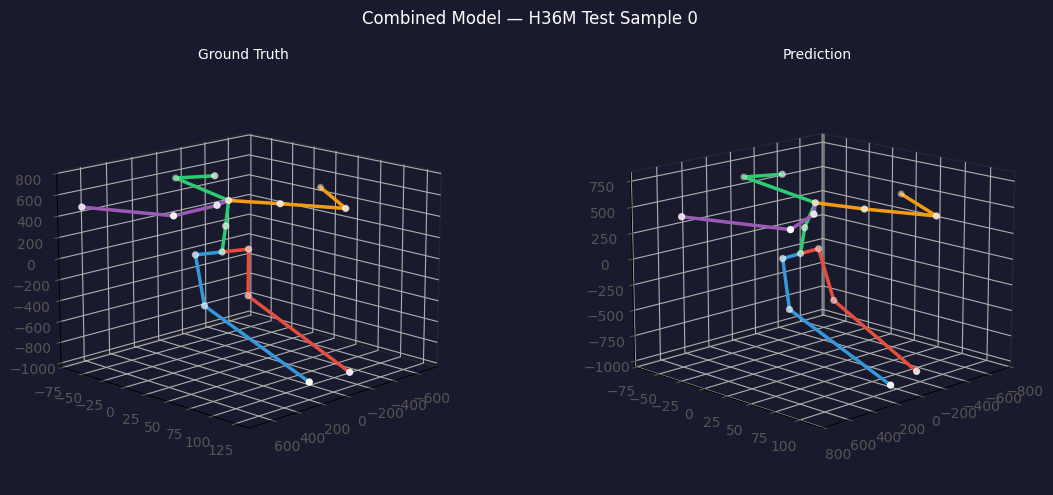

Saved: combined_skeleton_0.png


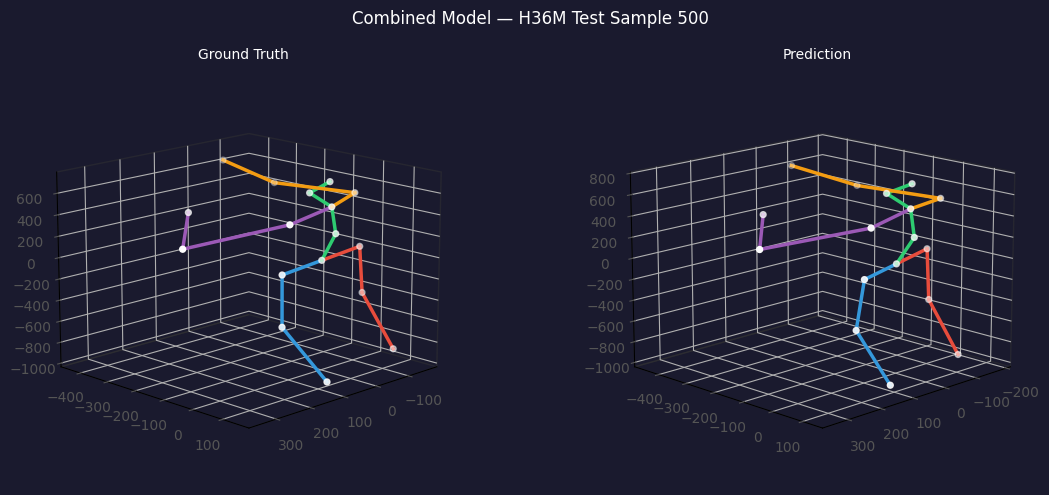

Saved: combined_skeleton_500.png


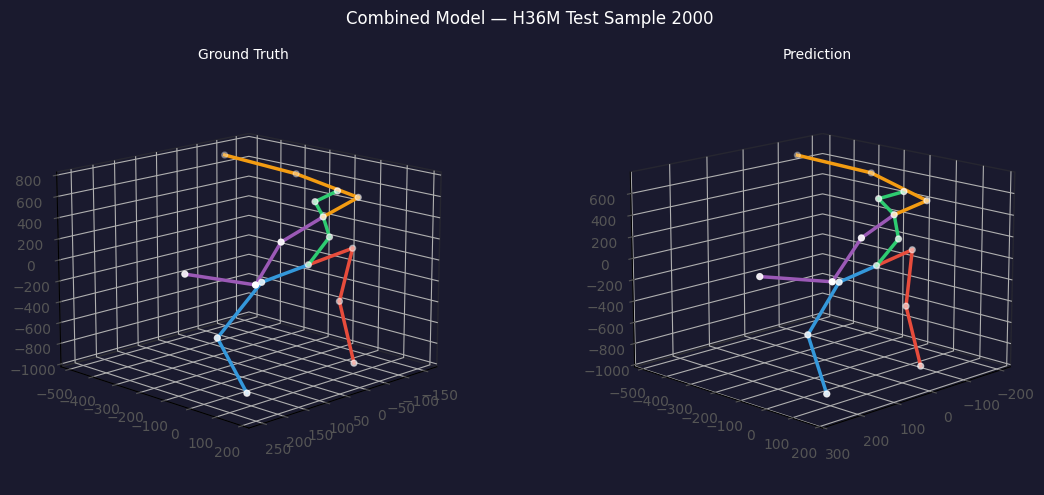

Saved: combined_skeleton_2000.png


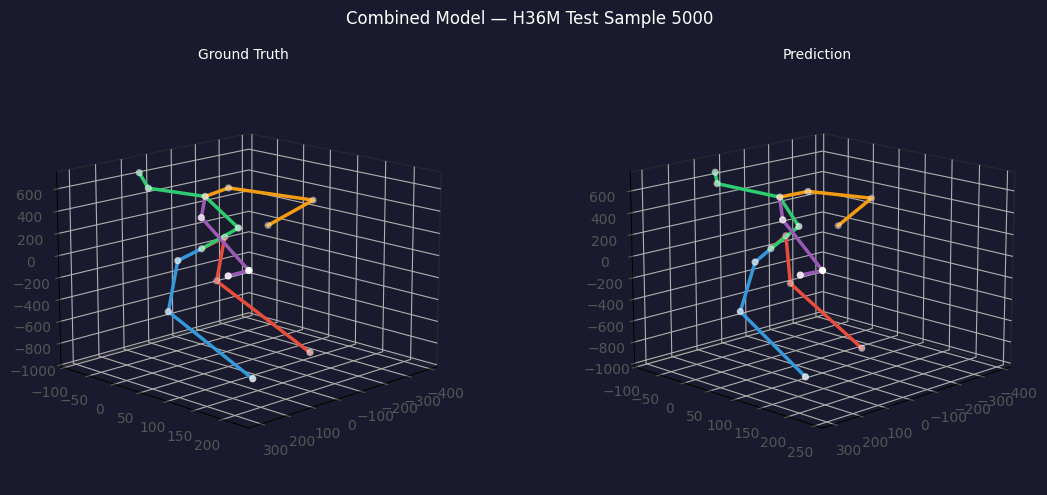

Saved: combined_skeleton_5000.png


In [21]:
# ─── 3D Skeleton Visualization ───────────────────────────────────────────────
BONE_COLORS_MAP = (
    ['#E74C3C']*3 + ['#3498DB']*3 + ['#2ECC71']*4 +
    ['#9B59B6']*3 + ['#F39C12']*3
)

def plot_skeleton(gt, pred, title=""):
    fig = plt.figure(figsize=(12,5), facecolor='#1a1a2e')
    fig.suptitle(title, color='white', fontsize=12)
    for col, (data, label) in enumerate([(gt,'Ground Truth'),(pred,'Prediction')]):
        ax = fig.add_subplot(1,2,col+1, projection='3d')
        ax.set_facecolor('#1a1a2e')
        ax.set_title(label, color='white', fontsize=10)
        ax.tick_params(colors='#555')
        for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
            pane.fill=False; pane.set_edgecolor('#333')
        for bi,(i,j) in enumerate(BONES):
            ax.plot([data[i,0],data[j,0]],[data[i,1],data[j,1]],[data[i,2],data[j,2]],
                    c=BONE_COLORS_MAP[bi], lw=2.5)
        ax.scatter(data[:,0],data[:,1],data[:,2], c='white', s=18, zorder=5)
        ax.view_init(elev=15, azim=45)
    plt.tight_layout()
    return fig

final.eval()
for idx in [0, 500, 2000, 5000]:
    X, Y = s2_test.datasets[0][idx]   # from H36M test
    with torch.no_grad():
        pred = final(X.unsqueeze(0).to(DEVICE)).cpu().view(17,3).numpy()
    gt = Y.view(17,3).numpy()
    fig = plot_skeleton(gt, pred, title=f"Combined Model — H36M Test Sample {idx}")
    fig.savefig(f"combined_skeleton_{idx}.png", dpi=120, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show()
    print(f"Saved: combined_skeleton_{idx}.png")
